<a href="https://colab.research.google.com/github/etorrey-vc/CMPU-250/blob/main/Torrey_Assignment_3_%7C_CMPU_250.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<abbr>CMPU</abbr>&thinsp;250 · Assignment 3

# Guidelines

- All data used in this assignment should only be downloaded **from Moodle**.

- Show the code you used to arrive at your answer.

- If you're unsure about your code, make a markdown cell and explain your logic. Even if you get the answer wrong, I may give you points for your explanation.

- Write good, readable code [according to Python style](https://peps.python.org/pep-0008/). You'll be graded in part on the formatting of your code.

- Points are assigned based on expected difficulty and expected length of time it takes to do each problem. "Challenge" problems are required, but will be less points because they're meant to challenge you. "Extra Credit" problems are not required.

# Run this code first

In [205]:
# run this first
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# suppress warnings
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

&nbsp;

# Assignment 3: Housing *(60 pts)*


For this assignment, we will be practicing more data preparation, descriptive and inferential statistics, and some prediction (machine learning). For this assignment, use the dataset `housing.csv`, available on Moodle.

Each row of the data contains the address and price of a single house, as well as information based on the area that it's in.

Here is a description of its contents:
- `Address`: address of house
- `Price`: price of the house
- `Avg. Area Income`: average annual income of people in the area of the house
- `Avg. Area House Age`: average age of houses in the area of the house
- `Avg. Area Number of Rooms`: average number of rooms of houses in the area
- `Avg. Area Number of Bedrooms`: average number of bedrooms of homes in the area
- `Area Population`: population in the area


&nbsp;

## Q1 (2 pts)

Load in the data, assign it to the name `housing`, and save a copy of the original.

In [206]:
# delete this comment, write your code here
housing = pd.read_csv("housing.csv")
housing

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,USNS Raymond\nFPO AE 09386
...,...,...,...,...,...,...,...
4995,60567.94414,7.830362,6.137356,3.46,22837.36103,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.27543,6.999135,6.576763,4.02,25616.11549,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.68689,7.250591,4.805081,2.13,33266.14549,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.33124,5.534388,7.130144,5.44,42625.62016,1.198657e+06,USS Wallace\nFPO AE 73316


&nbsp;

## Q2 (8 pts)

Separate the `Address` column into four columns: `State`, `Zip Code`, `Street Address`, and `Military Address`. The `Military Address` column should contain boolean values that indicate whether the address is a military address or not. (If you're unfamiliar, read about military addresses here: https://faq.usps.com/s/article/How-Do-I-Address-Military-Mail.) The `State` address should include all US states, as well as all other two-letter "state" abbreviations, like AA, PR, or GU.

For examples:
- `"208 Michael Ferry Apt. 674\nLaurabury, NE 37010-5101"` should be separated into:
  - `"NE"` (`State`),
  - `"37010-5101"` (`Zip Code`),
  - `"208 Michael Ferry Apt. 674"` (`Street Address`), and
  - `False` (`Military Address`).


- `"USNS Williams\nFPO AP 30153-7653"` should be separated into:
  - `"AP"` (`State`),
  - `"30153-7653"` (`Zip Code`),
  - `"USNS Williams"` (`Street Address`), and
  - `True` (`Military Address`).

*Hint: One way to do this problem is to use `.apply()` and `lambda` functions, along with a couple string methods. See the finished notebook for Class 3 for examples.*

In [207]:
address_split = housing["Address"].str.split("\n")

street = address_split.str[0]
address_info = address_split.str[1]
address_parts = address_info.str.split(" ")

# second to last elt of address breakdown
housing["State"] = address_parts.str[-2]

# last elt of address breakdown
housing["Zip Code"] = address_parts.str[-1]

housing["Street Address"] = street

# first elt of address breakdown, check for military identifiers per https://faq.usps.com/s/article/How-Do-I-Address-Military-Mail
housing["Military Address"] = address_parts.str[0].isin(["APO", "FPO", "DPO"])

housing = housing.drop(columns="Address")

In [208]:
housing

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,State,Zip Code,Street Address,Military Address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,NE,37010-5101,208 Michael Ferry Apt. 674,False
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,CA,48958,188 Johnson Views Suite 079,False
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,WI,06482-3489,9127 Elizabeth Stravenue,False
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,AP,44820,USS Barnett,True
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,AE,09386,USNS Raymond,True
...,...,...,...,...,...,...,...,...,...,...
4995,60567.94414,7.830362,6.137356,3.46,22837.36103,1.060194e+06,AP,30153-7653,USNS Williams,True
4996,78491.27543,6.999135,6.576763,4.02,25616.11549,1.482618e+06,AA,42991-3352,"PSC 9258, Box 8489",True
4997,63390.68689,7.250591,4.805081,2.13,33266.14549,1.030730e+06,VA,01707-9165,4215 Tracy Garden Suite 076,False
4998,68001.33124,5.534388,7.130144,5.44,42625.62016,1.198657e+06,AE,73316,USS Wallace,True


&nbsp;

## Q3 (2 pts)

- To double check your methods from Q2, print the number of unique zip codes in your dataset. (You should end up with 4958.)

- How many repeated entries are there in the `Street Address` column?

**Answer:**

- 4958 unique codes
- 15 repeat entries in the 'Street Address' column


In [209]:
unique_zips = len(housing["Zip Code"].unique())

address_counts = housing["Street Address"].value_counts()
address_counts = list(filter(lambda x: x > 1, address_counts))

print(str(unique_zips) + " unique codes")
print(str(len(address_counts)) + " repeat entries in the 'Street Address' column")

4958 unique codes
15 repeat entries in the 'Street Address' column


&nbsp;

## Q4 (3 pts)

- Count the number of entries by `State` (including the two-letter "state" abbreviations for military addresses and other US territories, like `AE`, `GU`, and `PR`).

- Plot the number of entries per `State`. Make sure your plot has a title and its axes have appropriate labels and readable ticks.

(*Hint: If you're unsure how to do all this, see [the documentation](https://matplotlib.org/3.5.3/api/_as_gen/matplotlib.pyplot.html).*)

**Answer:** See bar chart below

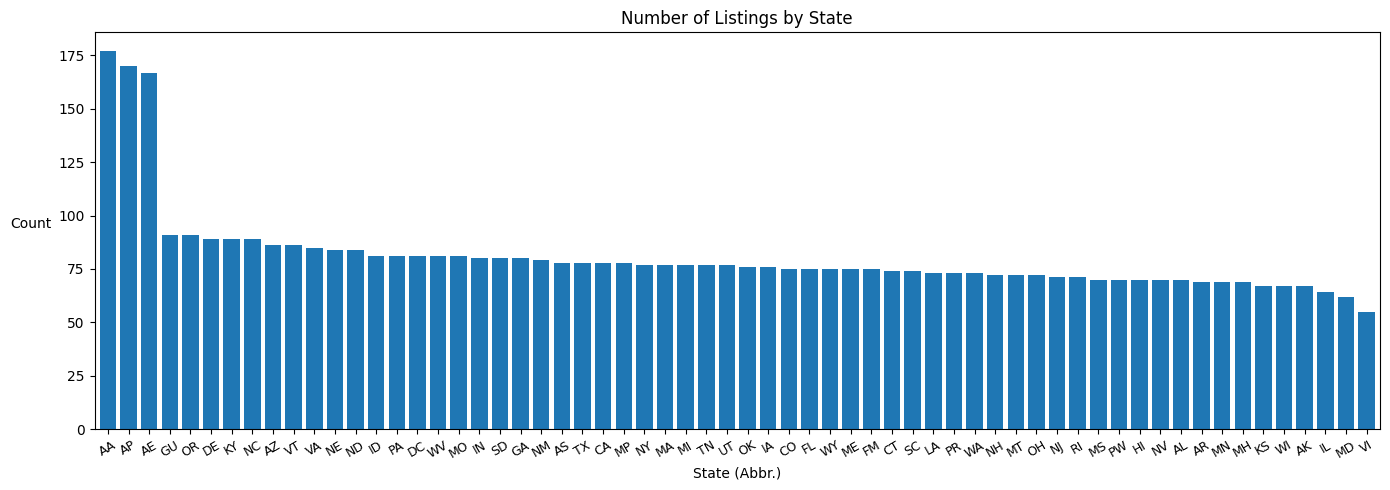

In [210]:
state_counts = housing["State"].value_counts()

plt.figure(figsize=(14, 5))
state_counts.plot(kind="bar",width=0.8)

plt.title("Number of Listings by State")

plt.xlabel("State (Abbr.)")
plt.xticks(rotation=30,fontsize=9)

plt.ylabel("Count",rotation=0,labelpad=20)

plt.tight_layout()
plt.show()

&nbsp;

## Q5 (3 pts)

- Generate descriptive statistics for all variables in our data, including the mean, minimum, maximum, and standard deviation.

Answer the following:
  - What is the standard deviation of price? In precise terms, explain what this measure tells us.
  - What's the maximum number of bedrooms in our data?
  - In which state is the entry with the smallest `Avg. Area Income` in our data?

**Answer:**
- The standard deviation of price is 3.536e+05, meaning that house prices are generally priced around \$353,600 away from the average house price, which is \$1,232,182.
- The max number of bedrooms in the data is 6.5
- The state with the smallest Avg. Area Income entry is actually an AA (Armed Forces) address, so the state is not given

In [211]:
housing

summary = housing.select_dtypes(include="number").agg(["mean", "min", "max", "std"])
print(summary)

housing.loc[housing["State"].idxmin(), "State"]

      Avg. Area Income  Avg. Area House Age  Avg. Area Number of Rooms  \
mean      68583.108984             5.977222                   6.987792   
min       17796.631190             2.644304                   3.236194   
max      107701.748400             9.519088                  10.759588   
std       10657.991214             0.991456                   1.005833   

      Avg. Area Number of Bedrooms  Area Population         Price  
mean                      3.981330     36163.516039  1.232182e+06  
min                       2.000000       172.610686  1.593866e+04  
max                       6.500000     69621.713380  2.469066e+06  
std                       1.234137      9925.650114  3.535618e+05  


'AA'

&nbsp;

## Q6 (2 pts)

Let's look at how prices are distributed.

- Plot the `Price` distribution --- you should choose an appropriate plot for this.

- Describe the distribution.
  - What kind of distribution does it look like? *(See Class 3 notebook for common distributions.)*
  - Is the distribution skewed? Explain.

**Answer:** The price reflects a normal distribution, resembling a bell curve. It does not seem to be skewed in any particular direction, the mean and the median values are almost identical.

In [212]:
print(housing["Price"].mean())
print(housing["Price"].median())

1232182.3716874465
1232872.356


Text(0.5, 1.0, 'Price distribution')

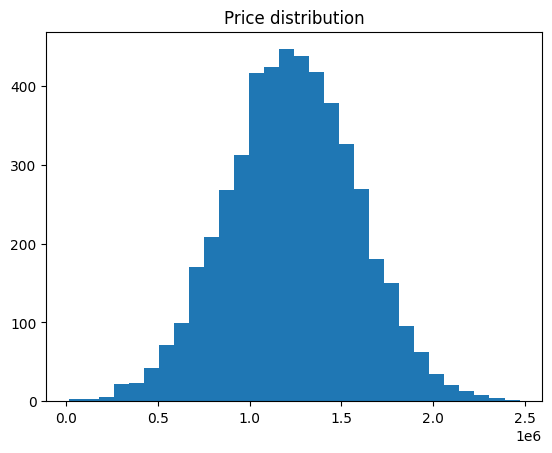

In [213]:
plt.hist(housing["Price"], bins=30)
plt.title("Price distribution")

&nbsp;

## Q7 (4 pts)

Let's look at correlation between variables in `housing`. Do the following:

- Display a correlation matrix between `Price` and all of the columns for which the label includes `Avg. Area`. Then, show a matrix plot of the correlation matrix to display it in colors using `matshow()`.

- Which variable is most highly-correlated with `Price`? Give a precise interpretation of what the correlation coefficient between this variable and `Price` means.

**Answer:** Average Area Income is most highly-correlated with Price. The correlation coefficient is around 0.641 for Average Area Income to Price. This means that for every change in Price, Average Area Income generally also sees a change that is around a 64.1% proportion of the change seen in Price. This is not surprising as higher prices would naturally attract higher incomes, and higher incomes would be more willing/capable of paying higher prices.

In [214]:
columns = ["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Avg. Area Number of Bedrooms", "Area Population", "Price"]

price_corr = housing[columns].corrwith(housing["Price"])

full_corr = housing[columns].corr()



price_corr

,0
Avg. Area Income,0.641314
Avg. Area House Age,0.453262
Avg. Area Number of Rooms,0.338445
Avg. Area Number of Bedrooms,0.174192
Area Population,0.406395
Price,1.000000


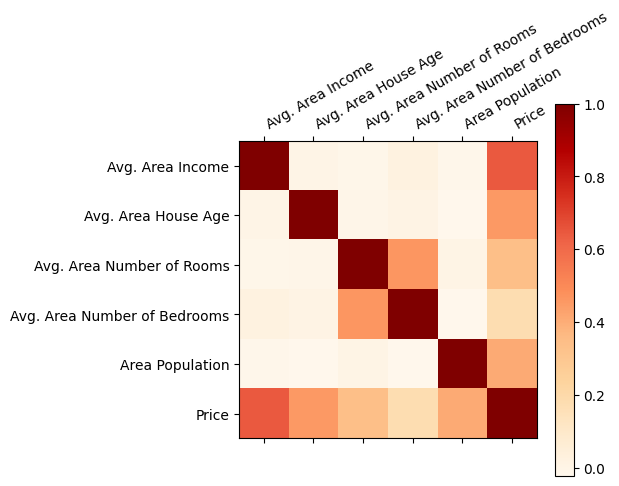

In [215]:
plt.matshow(full_corr, cmap="OrRd")
plt.xticks(range(0,6), columns, rotation=30, ha="left")
plt.yticks(range(0,6), columns)
plt.colorbar()
plt.show()


&nbsp;

## Q8-12 Imputing Missing Values

There's some missing `Price` values in our data. For questions Q8 through Q12, we're going to try three different approaches to handling them, then compare them.

Below is a description of the three approaches we'll use for handling missing values (as well as the dataframe we'll create associated with each method):

- Approach 1. Remove all entries with missing `Price` values from the data. (`housing_nona`)

- Approach 2. Fill in (impute) any missing values with the mean `Price`. (`housing_mean_impute`)

- Approach 3. Fit a linear model to predict prices and use it to fill in missing values in the `Price` column. (`housing_lm_impute`)

(*See the Class 3 notebook for methods related to finding and filling missing values.*)

&nbsp;

### Q8 (5 pts)

Let's do Approach 1 for handling missing values -- remove all entries with missing values. To do so, follow these steps:

1. Display the number of missing values in the `Price` column of `housing`.

2. Create a copy of `housing` and name it `housing_nona`. Remove all rows from `housing_nona` that contain missing values in the `Price` column.

3. Double-check that you removed all rows with missing `Price` values: Subtract the number of missing values in the `Price` column of `housing` from the total number of rows in `housing`. This should equal the total rows in `housing_nona` now.

**Answer:**

In [216]:
housing_nona = housing.copy()
rows = housing_nona[housing_nona["Price"].isnull()].index
housing_nona = housing_nona.drop(index=rows)

### Q9 (7 pts)

Now that we have a dataset without missing values, let's take a detour to practice *inferential statistics.*

- We aim to answer the following question: Are houses in New York State more or less expensive on average than houses in any other part of the country?

- To do so, perform a two-sample t-test comparing the mean price of houses in New York State (group 1) to the mean of all houses that are not in New York State (group 2).

- When interpreting the results of this t-test, be sure to comment on p-values and what they mean, in terms of hypothesis testing. (Assume that the sample is representative of the population --- there was no bias in data collection.)

*Hint: See Class 5 notebook for this problem.*

**Answer:** The null hypothesis in this test would be that houses in NY state are not more or less expensive on average than in any other part of the country. The p-value achieved through this t-test is 0.2889771614734227, which is greater than 0.05. This means that we accept the null hypothesis. In conclusion, the results of the test are not statistically significant and do not suggest that houses in NY state are on average more or less expensive than elsewhere.





In [217]:
import statsmodels.stats.weightstats as smw

# avg ny house price
group1 = housing_nona[housing_nona["State"] == "NY"]["Price"]

# avg all other region house price
group2 = housing_nona[housing_nona["State"] != "NY"]["Price"]

# two-sample t-test
t_stat, p_value, df = smw.ttest_ind(group1, group2)
print(p_value)

0.2889771614734227


&nbsp;

### Q10 (3 pts)

Let's go back to imputing missing values. Let's do Approach 2 described above:

- Calculate the mean `Price` in the dataframe `housing`.

- Create a copy of `housing` and give it the name `housing_mean_impute`. Then, fill the missing values in the `Price` column of `housing_mean_impute` with the mean value of `Price` in `housing`.

- Verify you performed this imputation correctly: Print the median `Price` in both dataframes `housing` and `housing_mean_impute`.

    *(The median price in `housing` should be slightly larger than that in `housing_mean_impute`.)*

**Answer:**

In [218]:
avg_price = housing["Price"].mean()

housing_mean_impute = housing.copy()
rows = housing_mean_impute[housing_mean_impute["Price"].isnull()].index
housing_mean_impute.loc[rows, "Price"] = avg_price

print(housing["Price"].median())
print(housing_mean_impute["Price"].median())

1232872.356
1232182.3716874465


&nbsp;

### Q11 (15 pts)

Finally, let's do Approach 3.

We're going to fit a linear model <u>to predict price</u>, then use the predicted price values to fill in our missing values. To do so, follow these steps:

1. (Feature selection) Use the `statsmodels` package for this problem. Using the `housing_nona` dataframe, fit a linear model where the outcome variable is `Price` and the explanatory variables are all columns in `housing_nona` with labels starting with `Avg. Area`. Report the model summary. (We'll use it in the next step.)

2. (Train-test split) Use the `sklearn` package for subproblems 2-5. Split the `housing_nona` dataset into test and training datasets.

3. (Model training) Train a predictive model on the training set from Step 2 to predict `Price`. For features, use every variable from Step 1 that is a statistically significant (p<.05) predictor of `Price`.

4. (Model testing) Print the mean-squared error (MSE) of your trained model on the test set. Predict the price of each house in the test set. Then, compare the predicted price to the ground truth values in the `Price` column of the test set.

5. Using your trained linear model, predict all the values in the `Price` column in the dataframe `housing`. (All values --- both the missing and non-missing values.)

6. Create a copy of `housing` and name it `housing_lm_impute`. Fill the missing values of `Price` in `housing_lm_impute` with the predicted values from Step 5. (Fill only the missing values with the predicted values, leave the non-missing values the same.)

    (*Hint: You can use `fillna()` to do this.*)

7. To double-check your results, run the following code:

      ``` housing_lm_impute['Price'].compare(housing['Price']) ```

      You should see an output like this:

      | | self	| other |
      | -- | --- | --- |
      | 8	| 7.655886e+05	| NaN |
      | 58	| 8.610202e+05	| NaN |
      | 82	| 1.103548e+06	| NaN |
      |93	| 1.358925e+06	| NaN |
      | 110 | 3.035676e+05	| NaN |
      | ...	| ...	| ... |

**Answer:**

1. linear model where the outcome variable is Price and the explanatory variables are all columns in housing_nona with labels starting with Avg. Area

In [219]:
import statsmodels.api as sm
import sklearn as sk
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split  # split data into train & test

# outcome variable
y = housing_nona["Price"]

# explanatory variables
X = housing_nona[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Avg. Area Number of Bedrooms"]]
X = sm.add_constant(X)

# fit model
model = sm.OLS(y, X).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.737
Model:                            OLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     3448.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:23:17   Log-Likelihood:                -66480.
No. Observations:                4915   AIC:                         1.330e+05
Df Residuals:                    4910   BIC:                         1.330e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                        -2.057e+06   2.93e+04    -70.237      0.000   -2.11e+06      -2e+06
Avg. Area Income                21.3585      0.243     88.045      0.000      20.883      21.834
Avg. Area House Age            1.63e+05   2607.904     62.507      0.000    1.58e+05    1.68e+05
Avg. Area Number of Rooms     1.227e+05   2896.119     42.367      0.000    1.17e+05    1.28e+05
Avg. Area Number of Bedrooms -1779.3687   2363.182     -0.753      0.452   -6412.262    2853.524
==============================================================================
Omnibus:                        0.753   Durbin-Watson:                   1.994
Prob(Omnibus):                  0.686   Jarque-Bera (JB):                0.700
Skew:                           0.019   Prob(JB):                        0.705
Kurtosis:                       3.045   Cond. No.                     7.88e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.88e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

2. split housing_nona dataset into test and training datasets

In [220]:
price_train, price_test = train_test_split(housing_nona, test_size = 0.2)

3. predictive model on the training set from Step 2 to predict "Price", using only statistically signficiant features

In [221]:
X_train = price_train[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms"]]
y_train = price_train["Price"]

model = LinearRegression().fit(X_train,y_train)

4. mean-squared error of the trained model on the test set

In [222]:
X_test = price_test[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms"]]
y_test = price_test["Price"]

# MSE
y_pred = model.predict(X_test)

errors = y_pred - y_test

print("Mean-squared error:", np.mean(errors ** 2))

Mean-squared error: 33170136625.850464


5. predict all the values in the "Price" column in the housing df

In [223]:
housing_pred = model.predict(housing[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms"]])

6. copy of housing with filled-in values of "Price" using the predicted values from step 5

In [224]:
housing_lm_impute = housing.copy()
housing_lm_impute["Price"] = housing_lm_impute["Price"].fillna(pd.Series(housing_pred))
# housing_lm_impute

housing_lm_impute['Price'].compare(housing['Price'])

,self,other
8,8.750968e+05,NaN
58,9.101983e+05,NaN
82,1.105383e+06,NaN
93,1.368850e+06,NaN
110,6.272274e+05,NaN
...,...,...
4701,1.073852e+06,NaN
4887,1.305968e+06,NaN
4888,1.370890e+06,NaN
4948,9.852667e+05,NaN


&nbsp;

### Q12 (6 pts)

Let's compare these three different ways of handling missing values. Do the following:

1. Using `statsmodels`, fit three separate linear models, one on `housing_nona`, one on `housing_mean_impute`, and one on `housing_lm_impute`. For each model, set the outcome variable as `Price` and the explanatory variables as all the columns starting with `Avg. Area`.

2. Which model has fits the data best? Explain your answer in precise terms with specific measures of goodness of fit from your model summaries.

3. Based on your answer in Step 2, which method of handling missing values do you think works best? Discuss why you think that is.

**Answer:** The models performed in the following order, although the differences seemed slight:
1. housing_lm_impute
2. housing_nona
3. housing_mean_impute

I ranked their performance based on the R-squared and F-statistic values. housing_lm_impute and housing_nona had a clear lead on housing_mean_impute. This makes sense. Simply inserting a mean value into the dataset 85 times would just strengthen that mean, shift the median, and does not seem like it would be superior to trimming empty values nor statistical modeling.

From a practical standpoint, being able to produce missing values using a model is probably the "best" way to handle missing values, but mostly because there are so many rows and so many variables that can be used to predict something like price. In this context, (real estate/housing market) it is both realistic and necessary to need to estimate the value of houses if the price is unknown, especially since we know that house price is almost always directly correlated with number of rooms/bedrooms, age, area income, etc. I think there could be contexts, however, where the "better" way to handle missing values would be to trim the dataset of those rows.

In [225]:
# model 1

# outcome variable
y = housing_nona["Price"]

# explanatory variables
X = housing_nona[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Avg. Area Number of Bedrooms"]]
X = sm.add_constant(X)

# fit model
model1 = sm.OLS(y, X).fit()

model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.737
Model:                            OLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     3448.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:23:18   Log-Likelihood:                -66480.
No. Observations:                4915   AIC:                         1.330e+05
Df Residuals:                    4910   BIC:                         1.330e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                        -2.057e+06   2.93e+04    -70.237      0.000   -2.11e+06      -2e+06
Avg. Area Income                21.3585      0.243     88.045      0.000      20.883      21.834
Avg. Area House Age            1.63e+05   2607.904     62.507      0.000    1.58e+05    1.68e+05
Avg. Area Number of Rooms     1.227e+05   2896.119     42.367      0.000    1.17e+05    1.28e+05
Avg. Area Number of Bedrooms -1779.3687   2363.182     -0.753      0.452   -6412.262    2853.524
==============================================================================
Omnibus:                        0.753   Durbin-Watson:                   1.994
Prob(Omnibus):                  0.686   Jarque-Bera (JB):                0.700
Skew:                           0.019   Prob(JB):                        0.705
Kurtosis:                       3.045   Cond. No.                     7.88e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.88e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [226]:
# model 2 - housing_mean_impute

# outcome variable
y = housing_mean_impute["Price"]

# explanatory variables
X = housing_mean_impute[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Avg. Area Number of Bedrooms"]]
X = sm.add_constant(X)

# fit model
model2 = sm.OLS(y, X).fit()

model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.728
Model:                            OLS   Adj. R-squared:                  0.728
Method:                 Least Squares   F-statistic:                     3348.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:23:18   Log-Likelihood:                -67672.
No. Observations:                5000   AIC:                         1.354e+05
Df Residuals:                    4995   BIC:                         1.354e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                        -2.019e+06   2.94e+04    -68.747      0.000   -2.08e+06   -1.96e+06
Avg. Area Income                21.0814      0.243     86.874      0.000      20.606      21.557
Avg. Area House Age           1.605e+05   2607.739     61.554      0.000    1.55e+05    1.66e+05
Avg. Area Number of Rooms     1.217e+05   2900.199     41.975      0.000    1.16e+05    1.27e+05
Avg. Area Number of Bedrooms -1237.2842   2363.947     -0.523      0.601   -5871.659    3397.091
==============================================================================
Omnibus:                        2.242   Durbin-Watson:                   1.980
Prob(Omnibus):                  0.326   Jarque-Bera (JB):                2.292
Skew:                           0.010   Prob(JB):                        0.318
Kurtosis:                       3.103   Cond. No.                     7.91e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.91e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [227]:
# model 3 - housing_lm_impute

# outcome variable
y = housing_lm_impute["Price"]

# explanatory variables
X = housing_lm_impute[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Avg. Area Number of Bedrooms"]]
X = sm.add_constant(X)

# fit model
model3 = sm.OLS(y, X).fit()

model3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     3552.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:23:18   Log-Likelihood:                -67587.
No. Observations:                5000   AIC:                         1.352e+05
Df Residuals:                    4995   BIC:                         1.352e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                        -2.057e+06   2.89e+04    -71.251      0.000   -2.11e+06      -2e+06
Avg. Area Income                21.3582      0.239     89.532      0.000      20.891      21.826
Avg. Area House Age            1.63e+05   2563.547     63.577      0.000    1.58e+05    1.68e+05
Avg. Area Number of Rooms     1.227e+05   2851.051     43.033      0.000    1.17e+05    1.28e+05
Avg. Area Number of Bedrooms -1749.3516   2323.887     -0.753      0.452   -6305.190    2806.487
==============================================================================
Omnibus:                        2.257   Durbin-Watson:                   1.989
Prob(Omnibus):                  0.324   Jarque-Bera (JB):                2.284
Skew:                           0.019   Prob(JB):                        0.319
Kurtosis:                       3.097   Cond. No.                     7.91e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.91e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

&nbsp;


&nbsp;

## Turning in your assignment

Before you export and turn in your code, you must restart your runtime and run all of your code. Then, export your code as an .ipynb file. Turn in just your .ipynb file on Gradescope (or Moodle).

**The outputs of your code must be displayed when you export your code in order to receive full credit.**